# 4. A/B 테스트 - Chunk 전략 비교

2번 노트북에서 이미 기존 RAG 답변 데이터셋을 만들었고, 3번 노트북에서 그 답변을 RAGAS로 평가했습니다.

따라서 이 노트북에서는 기존 RAG를 다시 구축하지 않습니다. 대신 **새로운 chunk 전략만 추가로 실행**한 뒤, 기존 결과와 비교합니다.

핵심 흐름은 다음과 같습니다.

1. 2번/3번 노트북의 기존 결과를 기준선으로 로드합니다.
2. 새로운 chunk 전략으로 Vector DB를 새로 만듭니다.
3. 같은 질문, 같은 프롬프트, 같은 답변 모델, 같은 `k`로 답변을 생성합니다.
4. 새 답변을 RAGAS로 평가합니다.
5. 기존 평가 결과와 새 평가 결과를 비교합니다.


## 비교할 실험 조건

비교의 목적은 chunk 전략 변경 효과를 보는 것입니다. 그래서 답변 모델, 프롬프트, 검색 개수는 2번 노트북과 동일하게 유지합니다.

| 구분 | 산출 위치 | chunk_size | chunk_overlap | retriever k | 답변 모델 |
| --- | --- | ---: | ---: | ---: | --- |
| 기존 기준선 | 2번/3번 노트북 결과 CSV | 500 | 50 | 4 | `gemma3:4b` |
| 새 chunk 전략 | 이 노트북에서 새로 생성 | 300 | 80 | 4 | `gemma3:4b` |

새 전략의 점수가 더 높을 수도 있고 낮을 수도 있습니다. 중요한 것은 같은 평가셋과 같은 지표로 실제 실행 결과를 비교하는 것입니다.


In [1]:
from __future__ import annotations

import ast
import json
from pathlib import Path

import pandas as pd
from datasets import Dataset
from dotenv import load_dotenv
from IPython.display import display
from langchain_qdrant import QdrantVectorStore
from langchain_community.document_loaders import PDFPlumberLoader
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import PromptTemplate
from langchain_ollama.chat_models import ChatOllama
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from qdrant_client import QdrantClient
from ragas import evaluate
from ragas.llms.base import LangchainLLMWrapper
from ragas.metrics import answer_relevancy, context_precision, context_recall, faithfulness

load_dotenv()

pd.set_option("display.max_colwidth", 120)

DATA_DIR = Path("./data")
PDF_PATH = DATA_DIR / "SPRI_AI_Brief_2023년12월호_F.pdf"
BASELINE_ANSWERS_PATH = DATA_DIR / "evaluation_answers_from_rag.csv"
BASELINE_SCORES_PATH = DATA_DIR / "evaluation_scores_from_ragas.csv"

NEW_ANSWERS_PATH = DATA_DIR / "evaluation_answers_chunk_strategy.csv"
NEW_SCORES_PATH = DATA_DIR / "evaluation_scores_chunk_strategy.csv"
COMPARISON_PATH = DATA_DIR / "evaluation_chunk_strategy_comparison.csv"

METRICS = [
    "answer_relevancy",
    "faithfulness",
    "context_recall",
    "context_precision",
]


In [2]:
def parse_list_column(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []

    text = str(value)
    for parser in (json.loads, ast.literal_eval):
        try:
            parsed = parser(text)
            return parsed if isinstance(parsed, list) else [str(parsed)]
        except (json.JSONDecodeError, ValueError, SyntaxError):
            continue
    return [text]


baseline_answers = pd.read_csv(BASELINE_ANSWERS_PATH)
baseline_scores = pd.read_csv(BASELINE_SCORES_PATH)

required_answer_columns = {"user_input", "reference", "reference_contexts"}
required_score_columns = {"user_input", *METRICS, "min_score", "diagnosis", "response", "reference"}

missing_answer_columns = required_answer_columns - set(baseline_answers.columns)
missing_score_columns = required_score_columns - set(baseline_scores.columns)

if missing_answer_columns:
    raise ValueError(f"기존 답변 CSV에 필수 컬럼이 없습니다: {sorted(missing_answer_columns)}")
if missing_score_columns:
    raise ValueError(f"기존 평가 CSV에 필수 컬럼이 없습니다: {sorted(missing_score_columns)}")

baseline_answers["reference_contexts"] = baseline_answers["reference_contexts"].apply(parse_list_column)

eval_questions = baseline_answers[["user_input", "reference", "reference_contexts"]].copy()

print(f"기존 기준선 답변 수: {len(baseline_answers)}")
print(f"기존 기준선 평가 수: {len(baseline_scores)}")
display(eval_questions.head())


기존 기준선 답변 수: 15
기존 기준선 평가 수: 15


,user_input,reference,reference_contexts
0,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,"바이든 대통령이 서명한 '안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령'은 AI의 안전과 보안 기준 마련, 개인정보 보호 등 광범위한 행정 조치를 명시하고 있습니다.","[1. 정책/법제 2. 기업/산업 3. 기술/연구 4. 인력/교육\n 미국, 안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령 발표\n KEY Contents\nn 미국 바이든 대통령이 ‘안전하고 신..."
1,주택 관련해서 AI가 어떻게 사용되나?,"형평성과 시민권 향상 차원에서 AI의 무책임한 사용으로 인한 차별과 편견을 방지하기 위한 조치를 확대하고, 주택 임대 시 AI 알고리즘 차별을 막기 위한 명확한 지침을 제공하고 있습니다.","[형평성과 시민권 향상 △소비자\n보호 △노동자 지원 △혁신과 경쟁 촉진 △국제협력을 골자로 함\n£바이든 대통령, AI 행정명령 통해 안전하고 신뢰할 수 있는 AI 개발과 활용 추진\nn 미국 바이든 대통령..."
2,"NAIRR의 목적은 무엇이며, 어떻게 미국 전역의 AI 연구를 촉진합니까?","NAIRR(국가AI연구자원)는 미국 전역의 AI 연구를 촉진하기 위해 설계된 프로그램으로, 중소기업과 개발자에게 기술과 인프라를 지원하여 국가 차원에서 AI 연구 인프라를 확충하는 것을 목표로 합니다.","[혁신과 경쟁 촉진 △국제협력을 골자로 함 £바이든 대통령, AI 행정명령 통해 안전하고 신뢰할 수 있는 AI 개발과 활용 추진 n 미국 바이든 대통령이 2023년 10월 30일 연방정부 차원에서 안전하고 신..."
3,미국에서 AI와 관련된 규제를 다루는 Executive Order의 목적은 무엇인가요?,"Executive Order on the Safe, Secure, and Trustworthy Development and Use of Artificial Intelligence (E.O. 14110)은 분야...","[분야의 전문 지식을 갖춘 외국인들이 미국에서 공부하고 취업할 수 있도록 지원 ☞ 출처 : The White House, Executive Order on the Safe, Secure, and Trustwo..."
4,"IDC에 따르면 2027년 AI 소프트웨어 매출이 2,500억 달러를 넘을 것인데, AI SIS와 AI AD&D의 성장률은 어떻게 되나요?","IDC의 예측에 의하면 AI 소프트웨어 시장은 2027년 2,510억 달러에 이를 것으로 보이며, AI SIS는 현재 매출 규모는 작지만 5년간 연평균 성장률이 32.6%로 시장 전체를 웃돌 전망입니다. 또한...","[<1-hop>\n\nSPRi AI Brief |\n2023-12월호\n IDC, 2027년 AI 소프트웨어 매출 2,500억 달러 돌파 전망\nKEY Contents\nn IDC의 예측에 의하면 AI 소프트..."


## 새 chunk 전략으로 Qdrant Vector DB 만들기

기존 결과는 그대로 두고, 새 chunk 전략용 Qdrant collection만 새로 만듭니다.

로컬 Qdrant는 `qdrant/` 폴더에서 `docker compose up -d`로 실행한 뒤 사용합니다. 기존 기준선과 비교하기 위해 `retriever k`는 2번 노트북과 같은 4로 유지합니다.


In [3]:
NEW_CHUNK_SIZE = 300
NEW_CHUNK_OVERLAP = 80

documents = PDFPlumberLoader(str(PDF_PATH)).load()

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=NEW_CHUNK_SIZE,
    chunk_overlap=NEW_CHUNK_OVERLAP,
)
split_documents = text_splitter.split_documents(documents)

print(f"PDF 페이지 수: {len(documents)}")
print(f"새 chunk 전략의 분할 문서 수: {len(split_documents)}")


PDF 페이지 수: 23
새 chunk 전략의 분할 문서 수: 129


In [4]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

QDRANT_URL = "http://localhost:6333"
COLLECTION_NAME = "chunk_size_300_overlap_80"
RETRIEVER_K = 4

# 같은 collection을 재실행할 때 문서가 중복 저장되지 않도록 Qdrant collection을 초기화합니다.
qdrant_client = QdrantClient(url=QDRANT_URL)
if qdrant_client.collection_exists(collection_name=COLLECTION_NAME):
    qdrant_client.delete_collection(collection_name=COLLECTION_NAME)

vectorstore = QdrantVectorStore.from_documents(
    documents=split_documents,
    embedding=embeddings,
    url=QDRANT_URL,
    collection_name=COLLECTION_NAME,
)

retriever = vectorstore.as_retriever(search_kwargs={"k": RETRIEVER_K})
print(f"검색 문맥 수(k): {RETRIEVER_K}")


검색 문맥 수(k): 4


### [Qdrant 접속](http://localhost:6333/dashboard#/collections)

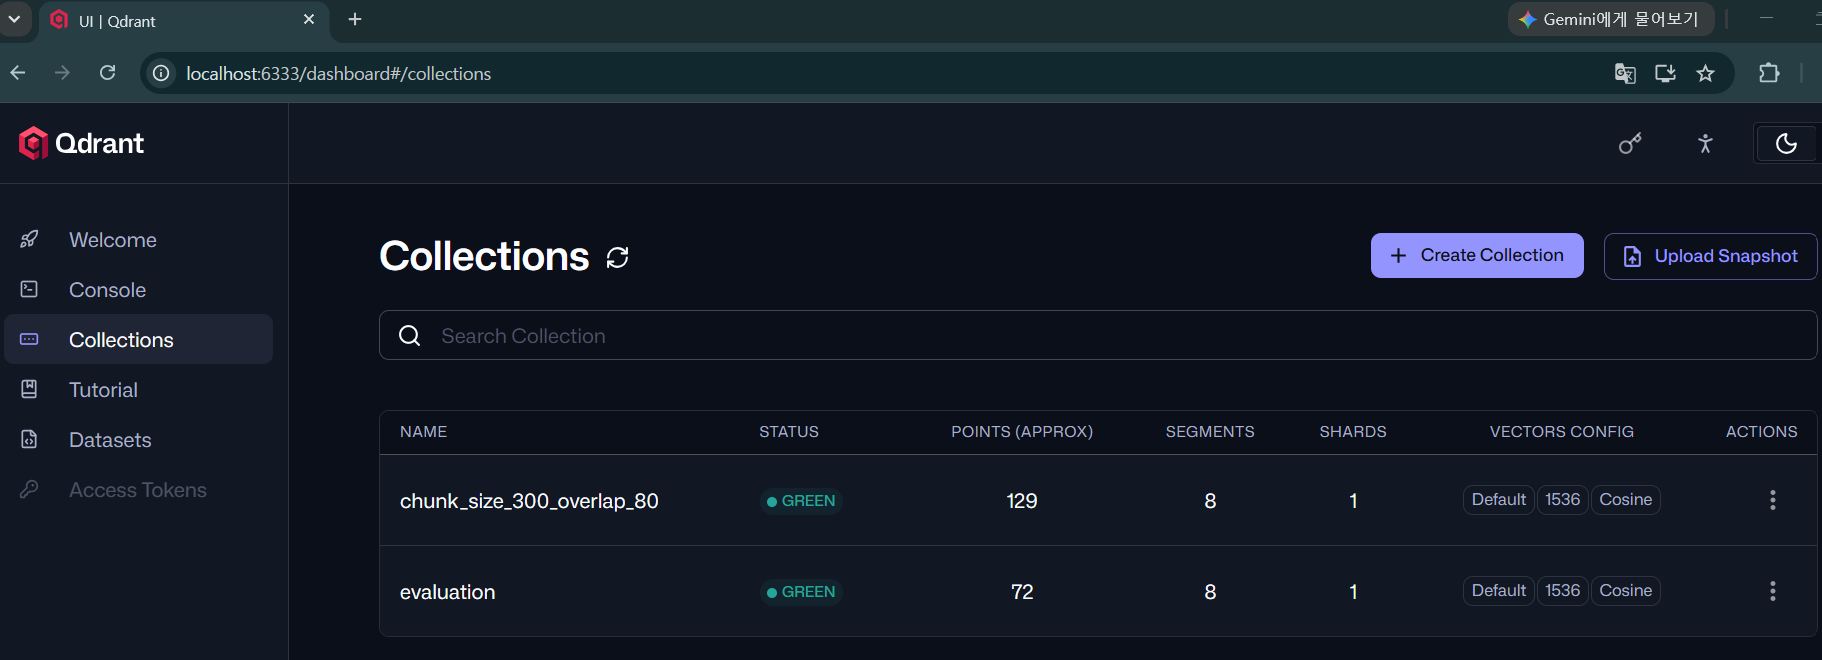

## 새 chunk 전략으로 답변 생성

프롬프트와 답변 모델은 2번 노트북과 같은 구조를 사용합니다. 이렇게 해야 chunk 전략 변경 효과를 더 깨끗하게 비교할 수 있습니다.


In [5]:
prompt = PromptTemplate.from_template(
    template="""
    - 당신은 질의응답 작업을 위한 어시스턴트입니다.
    - 아래에 제공된 검색/추출된 컨텍스트를 활용하여 질문에 답하십시오.
    - 답을 모를 경우, 모른다고 말하십시오.
    - 반드시 한국어로 답변해야 합니다.

    #컨텍스트:
    {context}

    #질문:
    {question}
    """
)

llm = ChatOllama(
    model="gemma3:4b",
    temperature=0.1,
    top_p=1.0,
    num_predict=256,
    keep_alive="5m",
)

answer_chain = prompt | llm | StrOutputParser()


In [6]:
def generate_answer(question: str) -> dict:
    retrieved_docs = retriever.invoke(question)
    contexts = [doc.page_content for doc in retrieved_docs]
    response = answer_chain.invoke(
        {
            "context": "\n".join(contexts),
            "question": question,
        }
    )
    return {
        "retrieved_contexts": contexts,
        "response": response,
    }


new_answer_rows = []

for row in eval_questions.itertuples(index=False):
    result = generate_answer(row.user_input)
    new_answer_rows.append(
        {
            "user_input": row.user_input,
            "retrieved_contexts": result["retrieved_contexts"],
            "response": result["response"],
            "reference": row.reference,
            "reference_contexts": row.reference_contexts,
        }
    )

new_answers = pd.DataFrame(new_answer_rows)
display(new_answers[["user_input", "response"]].head())


,user_input,response
0,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,"바이든 대통령의 행정명령은 AI의 안전과 보안 기준 마련, 개인정보 보호, 형평성과 시민권 향상, 소비자 보호, 노동자 지원, 혁신과 경쟁 촉진, 국제협력 등 다양한 내용을 포괄하고 있습니다. 특히 강력한 A..."
1,주택 관련해서 AI가 어떻게 사용되나?,"제공된 컨텍스트에 따르면, 주택 임대 시 AI 알고리즘 차별을 막기 위한 명확한 지침을 제공하는 것이 목표입니다. 즉, AI가 주택 임대 과정에서 불공정하게 작용하지 않도록 하는 데 초점을 맞추고 있습니다."
2,"NAIRR의 목적은 무엇이며, 어떻게 미국 전역의 AI 연구를 촉진합니까?",NAIRR(National Artificial Intelligence Research Resource)의 목적은 국가 차원에서 AI 연구 인프라를 확충하여 더 많은 AI 연구자에게 인프라를 지원하는 것입니다....
3,미국에서 AI와 관련된 규제를 다루는 Executive Order의 목적은 무엇인가요?,"미국에서 AI와 관련된 규제를 다루는 Executive Order의 목적은 안전하고 신뢰할 수 있는 AI 개발과 사용을 추진하는 것입니다. 이 행정명령은 AI의 안전 및 보안 기준 마련, 개인정보 보호, 형평..."
4,"IDC에 따르면 2027년 AI 소프트웨어 매출이 2,500억 달러를 넘을 것인데, AI SIS와 AI AD&D의 성장률은 어떻게 되나요?","IDC에 따르면 AI 소프트웨어 시장은 2027년 2,510억 달러로 달할 것으로 예상되며, AI SIS(AI 시스템 인프라 소프트웨어)는 5년간 연평균 성장률 32.6%를 기록하고, AI AD&D(AI 애플..."


In [7]:
new_answers_for_csv = new_answers.copy()
for column in ["retrieved_contexts", "reference_contexts"]:
    new_answers_for_csv[column] = new_answers_for_csv[column].apply(
        lambda value: json.dumps(value, ensure_ascii=False)
    )

new_answers_for_csv.to_csv(NEW_ANSWERS_PATH, index=False, encoding="utf-8-sig")
print(f"저장 완료: {NEW_ANSWERS_PATH}")


저장 완료: data\evaluation_answers_chunk_strategy.csv


## 새 답변 RAGAS 평가

새 chunk 전략으로 만든 답변만 RAGAS로 평가합니다. 기존 평가는 3번 노트북에서 만든 결과를 재사용합니다.


In [8]:
dataset_new = Dataset.from_pandas(
    new_answers[["user_input", "retrieved_contexts", "response", "reference", "reference_contexts"]],
    preserve_index=False,
)

# answer_relevancy는 기본 strictness=3이므로 실제 3회 생성을 받도록 RAGAS LLM wrapper를 사용합니다.
judge_llm = LangchainLLMWrapper(
    ChatOpenAI(model="gpt-4o-mini"),
    bypass_n=True,
)

result_new = evaluate(
    dataset=dataset_new,
    metrics=[answer_relevancy, faithfulness, context_recall, context_precision],
    llm=judge_llm,
)

new_scores = result_new.to_pandas()
new_scores[METRICS] = new_scores[METRICS].apply(pd.to_numeric, errors="coerce")
new_scores["min_score"] = new_scores[METRICS].min(axis=1)
display(new_scores[["user_input", *METRICS, "min_score"]].head())


Evaluating:   0%|          | 0/60 [00:00<?, ?it/s]

,user_input,answer_relevancy,faithfulness,context_recall,context_precision,min_score
0,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,0.839177,1.0,1.0,1.0,0.839177
1,주택 관련해서 AI가 어떻게 사용되나?,0.810333,1.0,1.0,1.0,0.810333
2,"NAIRR의 목적은 무엇이며, 어떻게 미국 전역의 AI 연구를 촉진합니까?",0.860718,1.0,1.0,1.0,0.860718
3,미국에서 AI와 관련된 규제를 다루는 Executive Order의 목적은 무엇인가요?,0.897455,1.0,1.0,1.0,0.897455
4,"IDC에 따르면 2027년 AI 소프트웨어 매출이 2,500억 달러를 넘을 것인데, AI SIS와 AI AD&D의 성장률은 어떻게 되나요?",0.874712,1.0,1.0,1.0,0.874712


In [9]:
LOW_SCORE_THRESHOLD = 0.70


def diagnose_rag_failure(row: pd.Series) -> str:
    retrieval_low = min(row["context_recall"], row["context_precision"]) < LOW_SCORE_THRESHOLD
    generation_low = min(row["answer_relevancy"], row["faithfulness"]) < LOW_SCORE_THRESHOLD

    if retrieval_low and generation_low:
        return "검색과 생성 모두 점검"
    if retrieval_low:
        return "검색 단계 우선 점검"
    if generation_low:
        return "생성 단계 우선 점검"
    return "큰 문제 없음"


new_scores["diagnosis"] = new_scores.apply(diagnose_rag_failure, axis=1)

score_output_columns = [
    "user_input",
    *METRICS,
    "min_score",
    "diagnosis",
    "response",
    "reference",
]

new_scores[score_output_columns].to_csv(NEW_SCORES_PATH, index=False, encoding="utf-8-sig")
print(f"저장 완료: {NEW_SCORES_PATH}")


저장 완료: data\evaluation_scores_chunk_strategy.csv


# A/B 테스트 평가 

## 기존 결과와 새 chunk 전략 비교

이제 3번 노트북에서 만든 기존 평가 결과와, 이 노트북에서 만든 새 chunk 전략 평가 결과를 비교합니다.


In [10]:
baseline_labeled = baseline_scores.copy()
baseline_labeled["config_name"] = "기존 기준선: 2번 노트북 결과"

new_labeled = new_scores[score_output_columns].copy()
new_labeled["config_name"] = "새 chunk 전략: size=300, overlap=80"

comparison_scores = pd.concat([baseline_labeled, new_labeled], ignore_index=True)

summary = (
    comparison_scores
    .assign(is_low_score=lambda df: df["min_score"] < LOW_SCORE_THRESHOLD)
    .groupby("config_name")
    .agg(
        answer_relevancy=("answer_relevancy", "mean"),
        faithfulness=("faithfulness", "mean"),
        context_recall=("context_recall", "mean"),
        context_precision=("context_precision", "mean"),
        min_score=("min_score", "mean"),
        low_score_count=("is_low_score", "sum"),
        sample_count=("user_input", "count"),
    )
    .round(4)
)

display(summary)


,answer_relevancy,faithfulness,context_recall,context_precision,min_score,low_score_count,sample_count
config_name,,,,,,,
기존 기준선: 2번 노트북 결과,0.7451,0.9270,0.8944,0.9333,0.6817,5,15
"새 chunk 전략: size=300, overlap=80",0.5669,0.8926,0.8056,0.8667,0.5374,7,15


In [11]:
baseline_name = "기존 기준선: 2번 노트북 결과"
new_name = "새 chunk 전략: size=300, overlap=80"

delta = (
    summary.loc[new_name, METRICS + ["min_score"]]
    - summary.loc[baseline_name, METRICS + ["min_score"]]
).to_frame("변화량")

metric_descriptions = {
    "answer_relevancy": "답변이 질문 의도에 얼마나 직접적으로 맞는지",
    "faithfulness": "답변이 검색된 문맥에 근거해 사실적으로 일관되는지",
    "context_recall": "기준 정답에 필요한 근거가 검색 문맥에 충분히 포함됐는지",
    "context_precision": "검색된 문맥 중 질문과 기준 정답에 관련 있는 내용이 얼마나 상위에 있는지",
    "min_score": "각 샘플의 네 지표 중 가장 낮은 점수의 평균으로, 전체 품질의 약한 고리를 보는 값",
}

delta.insert(0, "지표 설명", pd.Series(metric_descriptions))
delta["판단"] = delta["변화량"].apply(lambda value: "개선" if value > 0 else "하락/동일")
display(delta.round(4))


,지표 설명,변화량,판단
answer_relevancy,답변이 질문 의도에 얼마나 직접적으로 맞는지,-0.1782,하락/동일
faithfulness,답변이 검색된 문맥에 근거해 사실적으로 일관되는지,-0.0344,하락/동일
context_recall,기준 정답에 필요한 근거가 검색 문맥에 충분히 포함됐는지,-0.0888,하락/동일
context_precision,검색된 문맥 중 질문과 기준 정답에 관련 있는 내용이 얼마나 상위에 있는지,-0.0666,하락/동일
min_score,"각 샘플의 네 지표 중 가장 낮은 점수의 평균으로, 전체 품질의 약한 고리를 보는 값",-0.1443,하락/동일


## 질문별 변화 확인

평균 점수가 좋아져도 특정 질문에서는 나빠질 수 있습니다. 질문별 변화량을 확인해 어떤 유형에서 새 chunk 전략이 유리하거나 불리한지 봅니다.


In [12]:
question_delta = baseline_scores[["user_input", *METRICS, "min_score"]].merge(
    new_scores[["user_input", *METRICS, "min_score"]],
    on="user_input",
    how="inner",
    suffixes=("_baseline", "_new"),
)

for metric in [*METRICS, "min_score"]:
    question_delta[f"{metric}_delta"] = (
        question_delta[f"{metric}_new"] - question_delta[f"{metric}_baseline"]
    )

delta_columns = [
    "user_input",
    *[f"{metric}_delta" for metric in [*METRICS, "min_score"]],
]

display(
    question_delta[delta_columns]
    .sort_values("min_score_delta")
    .round(4)
)


,user_input,answer_relevancy_delta,faithfulness_delta,context_recall_delta,context_precision_delta,min_score_delta
11,"EU AI 법 협상에서 프랑스, 독일, 이탈리아의 제안이 '기반모델 전반 규제 반대'와 '자율 행동강령 의무화' 조건을 모두 만족한다면, 감독기관은 준수 여부와 제재를 어떻게 다루어야 하나요?",-0.8470,-0.7143,-1.0000,0.0,-0.8470
5,2023년 11월 8일 삼성 AI 포럼에서 공개된 삼성 가우스와 관련하여 구글의 앤스로픽 투자 소식은 어떤 연관이 있나요?,-0.8984,-0.0833,-0.3333,0.0,-0.6667
7,영국 AI 안전 연구소의 설립과 블레츨리 선언이 AI 시스템의 효과적 거버넌스와 투명성 향상에 어떻게 기여할 것으로 예상되나요?,-0.8497,0.3889,0.3333,0.0,-0.5000
12,영국 AI 안전성 정상회의의 외부 안전 테스트 합의와 영국 AI 안전 연구소의 핵심 기능은 어떻게 연결되나요? 두 문맥을 함께 사용해 설명하세요.,0.0034,0.0000,-0.3333,0.0,-0.1662
9,"AI 안전 연구소의 설립과 블레츨리 선언에서 언급된 AI 안전 테스트 계획은 어떻게 연결되며, 이들 간의 협력 방안은 무엇인가요?",-0.0561,-0.1250,0.0000,0.0,-0.0561
2,"NAIRR의 목적은 무엇이며, 어떻게 미국 전역의 AI 연구를 촉진합니까?",-0.0087,0.0000,0.0000,0.0,-0.0087
1,주택 관련해서 AI가 어떻게 사용되나?,-0.0067,0.0000,0.0000,-0.0,-0.0067
0,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,-0.0065,0.0000,0.0000,0.0,-0.0065
3,미국에서 AI와 관련된 규제를 다루는 Executive Order의 목적은 무엇인가요?,-0.0030,0.0000,0.0000,-0.0,-0.0030
4,"IDC에 따르면 2027년 AI 소프트웨어 매출이 2,500억 달러를 넘을 것인데, AI SIS와 AI AD&D의 성장률은 어떻게 되나요?",0.0000,0.0000,0.0000,0.0,0.0000


In [13]:
comparison_scores[
    [
        "config_name",
        "user_input",
        *METRICS,
        "min_score",
        "diagnosis",
        "response",
        "reference",
    ]
].to_csv(COMPARISON_PATH, index=False, encoding="utf-8-sig")

print(f"저장 완료: {COMPARISON_PATH}")


저장 완료: data\evaluation_chunk_strategy_comparison.csv


## 낮은 점수 샘플 확인

평균 점수만으로는 개선 여부를 판단하지 않습니다. 새 chunk 전략에서 여전히 낮은 점수로 남은 질문을 직접 확인합니다.


In [14]:
low_cases_new = (
    new_labeled
    .loc[new_labeled["min_score"] < LOW_SCORE_THRESHOLD, ["user_input", *METRICS, "min_score", "diagnosis", "response", "reference"]]
    .sort_values("min_score")
)

print(f"새 chunk 전략의 낮은 점수 샘플 수: {len(low_cases_new)}")
display(low_cases_new)


새 chunk 전략의 낮은 점수 샘플 수: 7


,user_input,answer_relevancy,faithfulness,context_recall,context_precision,min_score,diagnosis,response,reference
5,2023년 11월 8일 삼성 AI 포럼에서 공개된 삼성 가우스와 관련하여 구글의 앤스로픽 투자 소식은 어떤 연관이 있나요?,0.000000,0.750000,0.333333,1.0,0.000000,검색과 생성 모두 점검,"제공된 컨텍스트에 따르면, 구글은 차세대 AI 모델을 개발하기 위해 앤스로픽에 최대 20억 달러를 투자하는 추세에 있으며, 이는 아마존과 마이크로소프트 등 다른 클라우드 사업자들이 오픈AI와 협력하는 것과 유...","2023년 11월 8일 삼성 AI 포럼에서 삼성전자가 자체 개발한 생성 AI 모델 ‘삼성 가우스’를 공개했습니다. 같은 날 블룸버그 보도에 따르면, 구글은 앤스로픽과 4년간 30억 달러 규모의 클라우드 서비스..."
7,영국 AI 안전 연구소의 설립과 블레츨리 선언이 AI 시스템의 효과적 거버넌스와 투명성 향상에 어떻게 기여할 것으로 예상되나요?,0.000000,0.888889,1.000000,1.0,0.000000,생성 단계 우선 점검,"제공된 컨텍스트에는 영국 AI 안전 연구소의 설립과 관련된 내용만 언급되어 있으며, “블레츨리 선언”에 대한 정보는 포함되어 있지 않습니다.\n\n영국 AI 안전 연구소는 첨단 AI 시스템 평가 개발 및 시행...",영국 AI 안전 연구소는 첨단 AI 시스템 평가와 AI 안전 연구를 통해 AI 시스템의 효과적 거버넌스를 위한 도구 개발 및 안전한 AI 시스템 개발을 위한 새로운 접근 방식을 연구할 계획입니다. 블레츨리 선...
11,"EU AI 법 협상에서 프랑스, 독일, 이탈리아의 제안이 '기반모델 전반 규제 반대'와 '자율 행동강령 의무화' 조건을 모두 만족한다면, 감독기관은 준수 여부와 제재를 어떻게 다루어야 하나요?",0.000000,0.285714,0.000000,1.0,0.000000,검색과 생성 모두 점검,"제공된 컨텍스트에 따르면, 프랑스, 독일, 이탈리아는 기반모델에 대한 모든 유형의 규제에 반대하며, 자율적 행동강령 도입 및 준수를 의무화하는 방안을 제안했습니다. 이러한 제안이 최종적으로 AI 법에 반영된다...","프랑스, 독일, 이탈리아는 기반모델 전반 규제가 기술 중립적이고 위험 기반의 AI 규제 원칙에 어긋난다고 보고, 특정 용도로 사용될 수 있는 AI 시스템에 대한 규제를 요구했습니다. 동시에 자발적인 행동강령을..."
13,이 문서만 근거로 2024년에 최종 통과된 EU AI Act의 조항과 시행 일정을 설명해 주세요.,0.000000,1.000000,1.000000,0.0,0.000000,검색과 생성 모두 점검,"제공된 문서에는 2024년에 최종 통과된 EU AI Act의 조항이나 시행 일정에 대한 정보가 없습니다. \n\n문서에서는 유럽의회, EU 집행위원회, EU 이사회가 ‘AI 법(AI act)’에 대한 최종 협...","제공된 SPRI 2023년 12월 문서는 EU AI 법의 최종 통과 이후 조항이나 시행 일정을 다루지 않습니다. 문서에는 2023년 10월 24일 3자 협상 회의의 기본 합의, 2023년 11월 10일 통신작..."
14,"LG Aimers 4기의 교육 일정, 지원 자격, 과제 제출 방식을 알려 주세요.",0.000000,1.000000,0.666667,0.0,0.000000,검색과 생성 모두 점검,"제공된 컨텍스트에는 LG Aimers 4기의 교육 일정, 지원 자격, 과제 제출 방식에 대한 정보가 없습니다. 컨텍스트는 AI 관련 학회 및 연구 동향에 대한 정보를 제공하고 있습니다.","현재 평가용 RAG 코퍼스는 SPRI AI Brief 2023년 12월호 문서를 사용합니다. 이 문맥에는 LG Aimers 4기의 교육 일정, 지원 자격, 과제 제출 방식이 포함되어 있지 않습니다. 문서 기반..."
10,"AI 행정명령과 G7 국제 행동강령을 비교해, 둘 다 공통으로 요구하는 위험 관리 조치 2가지와 G7 행동강령에 더 구체적으로 나온 조치 1가지를 구분해서 답하세요.",0.841957,0.714286,0.666667,1.0,0.666667,검색 단계 우선 점검,## AI 행정명령과 G7 국제 행동강령 비교\n\n**공통으로 요구하는 위험 관리 조치 (2가지):**\n\n1. **AI 수명주기 전반에 걸친 위험 평가 및 완화:** 두 모두 첨단 AI 시스템 개발 과...,두 문서 모두 첨단 AI 시스템의 위험을 평가하고 완화하는 조치와 투명성/책임성 강화를 요구합니다. 미국 AI 행정명령은 강력한 AI 시스템 개발 기업이 안전 테스트 결과와 주요 정보를 미국 정부와 공유하도록...
12,영국 AI 안전성 정상회의의 외부 안전 테스트 합의와 영국 AI 안전 연구소의 핵심 기능은 어떻게 연결되나요? 두 문맥을 함께 사용해 설명하세요.,0.836228,1.000000,0.666667,1.0,0.666667,검색 단계 우선 점검,영국 AI 안전성 정상회의에서 28개국이 첨단 AI 모델에 대한 안전성 시험 계획 수립과 테스트 수행을 주도할 영국 AI 안전 연구소의 출범을 합의했습니다. 영국 AI 안전 연구소는 첨단 AI 시스템 평가 개...,"AI 안전성 정상회의에서는 첨단 AI 모델에 대한 정부 주도의 외부 안전 테스트에 합의했고, 테스트 결과가 다른 국가와 관련될 경우 공유하며 공동 표준 개발을 위해 노력하기로 했습니다. 영국 AI 안전 연구소..."
